# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv('data/cleaned_aviation_data.csv', parse_dates=['Event.Date'], low_memory=False)
print(df.shape)

# consistent look for all charts: blue = small aircraft, orange = large aircraft
sns.set_theme(style='whitegrid', context='notebook')
COL = {'Small': '#2a78d6', 'Large': '#eb6834'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
df.head()

(59990, 34)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,_make,_key,Total.Passengers,Fatal.Serious.Fraction,Destroyed,Plane.Type
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,VMC,Approach,Probable Cause,NaN,CESSNA,CESSNA|182P,4.0,0.0,0,CESSNA 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,...,VMC,Landing,Probable Cause,NaN,CESSNA,CESSNA|182RG,2.0,0.0,0,CESSNA 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,...,VMC,Takeoff,Probable Cause,NaN,CESSNA,CESSNA|182P,1.0,0.0,0,CESSNA 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,...,VMC,Approach,Probable Cause,NaN,PIPER,PIPER|PA-28R-200,2.0,0.0,0,PIPER PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,NaN,NaN,SPRINGBROOK,...,VMC,Landing,Probable Cause,NaN,CESSNA,CESSNA|140,2.0,0.0,0,CESSNA 140


In [3]:
print(df.columns.tolist())

['Event.Id', 'Investigation.Type', 'Accident.Number', 'Event.Date', 'Location', 'Country', 'Latitude', 'Longitude', 'Airport.Code', 'Airport.Name', 'Injury.Severity', 'Aircraft.damage', 'Aircraft.Category', 'Registration.Number', 'Make', 'Model', 'Amateur.Built', 'Number.of.Engines', 'Engine.Type', 'Purpose.of.flight', 'Total.Fatal.Injuries', 'Total.Serious.Injuries', 'Total.Minor.Injuries', 'Total.Uninjured', 'Weather.Condition', 'Broad.phase.of.flight', 'Report.Status', 'Publication.Date', '_make', '_key', 'Total.Passengers', 'Fatal.Serious.Fraction', 'Destroyed', 'Plane.Type']


In [4]:
df[['Total.Passengers', 'Fatal.Serious.Fraction', 'Destroyed']].describe()

,Total.Passengers,Fatal.Serious.Fraction,Destroyed
count,59990.000000,59990.000000,59990.000000
mean,5.161977,0.270849,0.211335
std,24.828846,0.429364,0.408259
min,1.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000
50%,2.000000,0.000000,0.000000
75%,2.000000,0.666667,0.000000
max,699.000000,1.000000,1.000000


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [ ]:
**How we split small vs large aircraft**

The brief says to use a passenger threshold of 20. Classifying per accident would put the same model in both groups, and using each model's maximum is fooled by data errors (a 4-seat Piper recorded with 90 people). So each **Plane.Type** (Make + Model) is **Large** if at least **25% of its accidents had 20 or more people aboard**, otherwise **Small**. Every accident inherits its plane type's size.

In [7]:
THRESHOLD = 20
type_stats = df.groupby('Plane.Type')['Total.Passengers'].agg(
    n_events='size',
    share_big=lambda s: (s >= THRESHOLD).mean())
large_types = type_stats[type_stats['share_big'] >= 0.25].index
df['Size'] = np.where(df['Plane.Type'].isin(large_types), 'Large', 'Small')

print(df['Size'].value_counts())
display(df[df['Size']=='Large']['Plane.Type'].value_counts().head(8))
display(df[df['Size']=='Small']['Plane.Type'].value_counts().head(5))

Size
Small    58424
Large     1566
Name: count, dtype: int64


Plane.Type
BOEING 737                121
BOEING 747                 31
BOMBARDIER CL-600-2B19     27
BOEING 737-200             26
BOEING 737-300             25
BOEING 777                 24
BOEING 727-200             24
BOEING 767                 23
Name: count, dtype: int64

Plane.Type
CESSNA 152         2211
CESSNA 172         1614
CESSNA 172N        1081
PIPER PA-28-140     857
CESSNA 172M         755
Name: count, dtype: int64

In [8]:
def safety_table(data, by, min_n=10):
    g = data.groupby(by)
    out = g.agg(n=('Destroyed', 'size'),
                mean_frac=('Fatal.Serious.Fraction', 'mean'),
                std_frac=('Fatal.Serious.Fraction', 'std'),
                destroyed_rate=('Destroyed', 'mean'))
    out['frac_ci95'] = 1.96 * out['std_frac'] / np.sqrt(out['n'])
    out['destroyed_ci95'] = 1.96 * np.sqrt(out['destroyed_rate'] * (1 - out['destroyed_rate']) / out['n'])
    return out[out['n'] >= min_n]

small = df[df['Size'] == 'Small']
large = df[df['Size'] == 'Large']
overall = df.groupby('Size').agg(n=('Destroyed','size'), mean_frac=('Fatal.Serious.Fraction','mean'), destroyed_rate=('Destroyed','mean'))
overall

,n,mean_frac,destroyed_rate
Size,,,
Large,1566,0.106668,0.118135
Small,58424,0.275249,0.213833


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [ ]:
Robustness rule: a make must have **at least 10 accidents inside its size group** before its average is shown. Bars show the 95% confidence interval, and `n` is printed next to each make so the reader can judge how much data stands behind it.

makes with >= 10 accidents  ->  small: 55 | large: 11


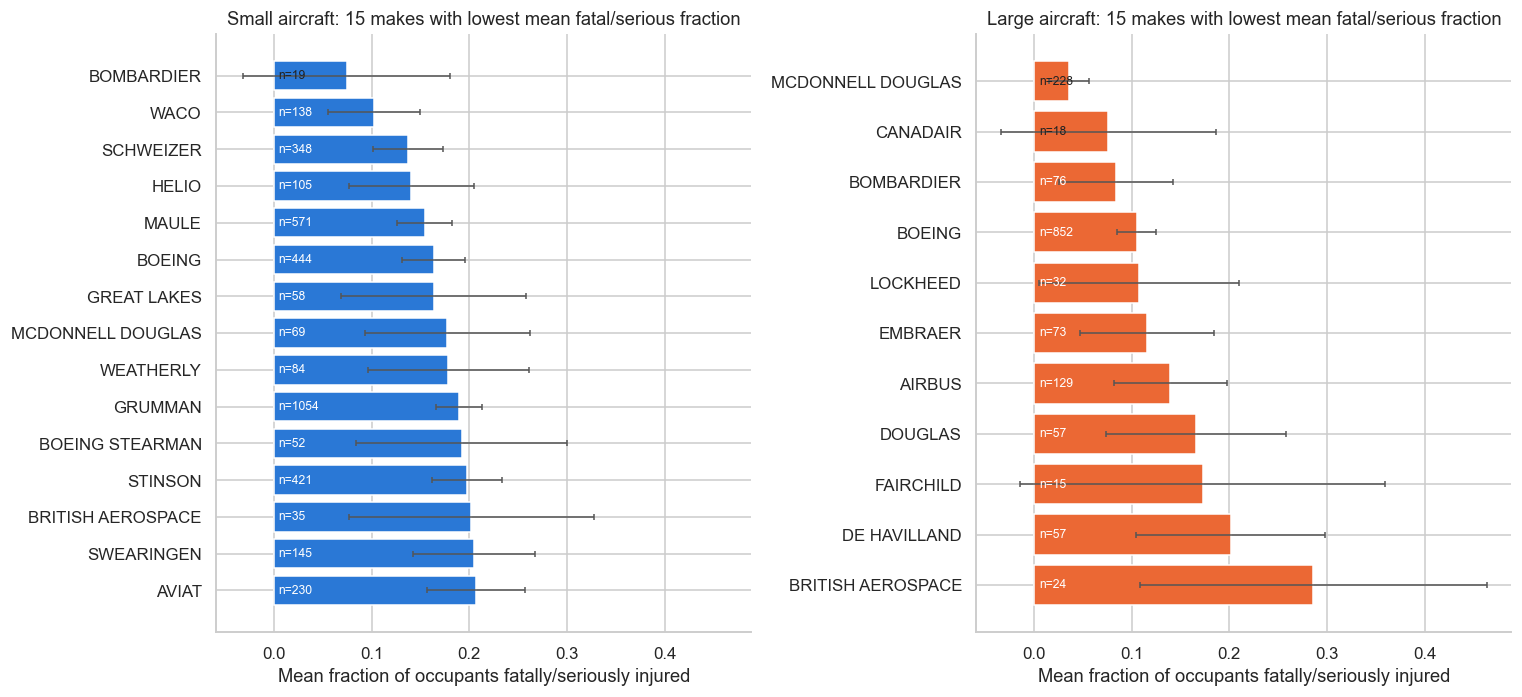

,n,mean_frac,std_frac,destroyed_rate,frac_ci95,destroyed_ci95
Make,,,,,,
BOMBARDIER,19,0.075,0.236,0.053,0.106,0.100
WACO,138,0.103,0.284,0.087,0.047,0.047
SCHWEIZER,348,0.137,0.341,0.201,0.036,0.042
HELIO,105,0.141,0.334,0.124,0.064,0.063
MAULE,571,0.154,0.345,0.093,0.028,0.024
BOEING,444,0.164,0.347,0.126,0.032,0.031
GREAT LAKES,58,0.164,0.367,0.138,0.095,0.089
MCDONNELL DOUGLAS,69,0.178,0.359,0.246,0.085,0.102
WEATHERLY,84,0.179,0.385,0.214,0.082,0.088


,n,mean_frac,std_frac,destroyed_rate,frac_ci95,destroyed_ci95
Make,,,,,,
MCDONNELL DOUGLAS,228,0.036,0.156,0.070,0.020,0.033
CANADAIR,18,0.076,0.238,0.111,0.110,0.145
BOMBARDIER,76,0.084,0.260,0.079,0.058,0.061
BOEING,852,0.105,0.293,0.112,0.020,0.021
LOCKHEED,32,0.108,0.295,0.156,0.102,0.126
EMBRAER,73,0.116,0.300,0.110,0.069,0.072
AIRBUS,129,0.140,0.334,0.155,0.058,0.062
DOUGLAS,57,0.166,0.354,0.158,0.092,0.095
FAIRCHILD,15,0.173,0.368,0.200,0.186,0.202


In [9]:
MIN_N = 10
small_makes = safety_table(small, 'Make', MIN_N)
large_makes = safety_table(large, 'Make', MIN_N)
print('makes with >= 10 accidents  ->  small:', len(small_makes), '| large:', len(large_makes))

low_small = small_makes.nsmallest(15, 'mean_frac')
low_large = large_makes.nsmallest(15, 'mean_frac')

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharex=True)
for ax, tbl, name in zip(axes, [low_small, low_large], ['Small', 'Large']):
    ax.barh(tbl.index, tbl['mean_frac'], xerr=tbl['frac_ci95'], color=COL[name], error_kw={'ecolor': '#555', 'lw': 1, 'capsize': 2})
    for y, (m, r) in enumerate(tbl.iterrows()):
        ax.text(0.005, y, f"n={int(r['n'])}", va='center', fontsize=8, color='white' if r['mean_frac'] > 0.08 else '#222')
    ax.invert_yaxis()
    ax.set_title(f'{name} aircraft: 15 makes with lowest mean fatal/serious fraction')
    ax.set_xlabel('Mean fraction of occupants fatally/seriously injured')
    ax.set_ylabel('')
plt.tight_layout()
plt.savefig('images/makes_mean_fraction.png', bbox_inches='tight')
plt.show()
display(low_small.round(3)); display(low_large.round(3))

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

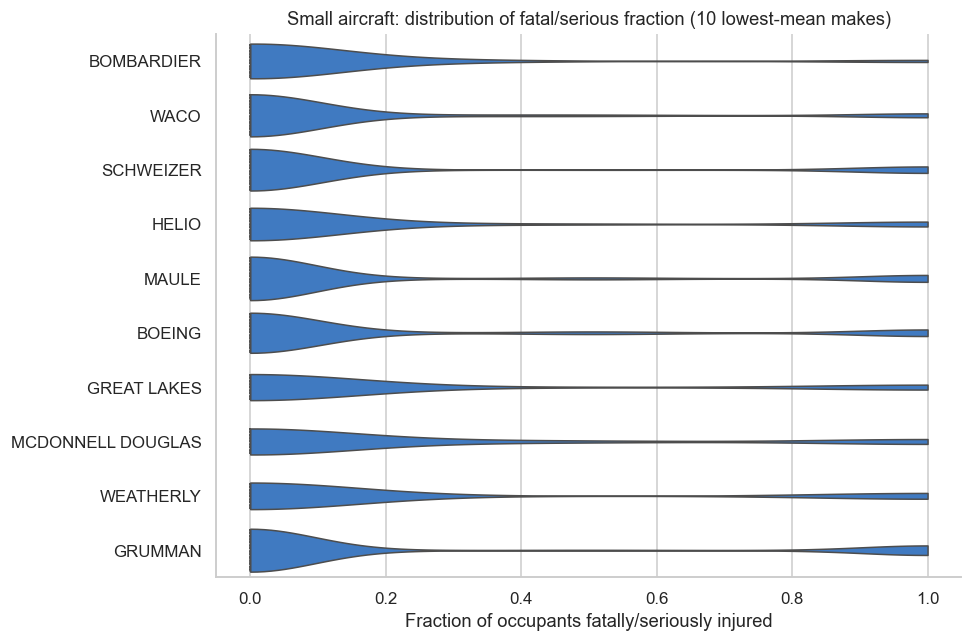

In [10]:
order = low_small.nsmallest(10, 'mean_frac').index
plt.figure(figsize=(9, 6))
sns.violinplot(data=small[small['Make'].isin(order)], x='Fatal.Serious.Fraction', y='Make', order=order,
               orient='h', cut=0, inner='quartile', color=COL['Small'], linewidth=1)
plt.title('Small aircraft: distribution of fatal/serious fraction (10 lowest-mean makes)')
plt.xlabel('Fraction of occupants fatally/seriously injured'); plt.ylabel('')
plt.tight_layout(); plt.savefig('images/small_makes_violin.png', bbox_inches='tight'); plt.show()

In [11]:
# the distribution is bimodal (mostly 0 or 1): share of accidents with NO serious/fatal injury, and with EVERYONE
small[small['Make'].isin(order)].groupby('Make')['Fatal.Serious.Fraction'].agg(
    pct_zero=lambda s: (s == 0).mean(), pct_all=lambda s: (s == 1).mean(), median='median').loc[order].round(2)

,pct_zero,pct_all,median
Make,,,
BOMBARDIER,0.84,0.05,0.0
WACO,0.87,0.08,0.0
SCHWEIZER,0.86,0.13,0.0
HELIO,0.83,0.12,0.0
MAULE,0.82,0.13,0.0
BOEING,0.80,0.13,0.0
GREAT LAKES,0.83,0.16,0.0
MCDONNELL DOUGLAS,0.77,0.14,0.0
WEATHERLY,0.82,0.18,0.0


**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

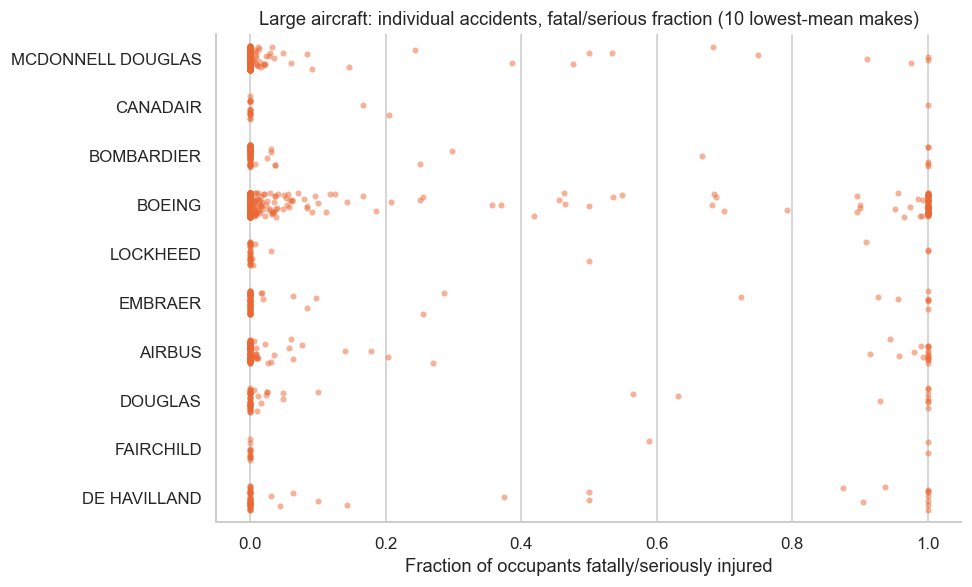

In [12]:
order_l = low_large.nsmallest(10, 'mean_frac').index
plt.figure(figsize=(9, 5.5))
sns.stripplot(data=large[large['Make'].isin(order_l)], x='Fatal.Serious.Fraction', y='Make', order=order_l,
              orient='h', jitter=0.25, alpha=0.5, size=4, color=COL['Large'])
plt.title('Large aircraft: individual accidents, fatal/serious fraction (10 lowest-mean makes)')
plt.xlabel('Fraction of occupants fatally/seriously injured'); plt.ylabel('')
plt.tight_layout(); plt.savefig('images/large_makes_strip.png', bbox_inches='tight'); plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

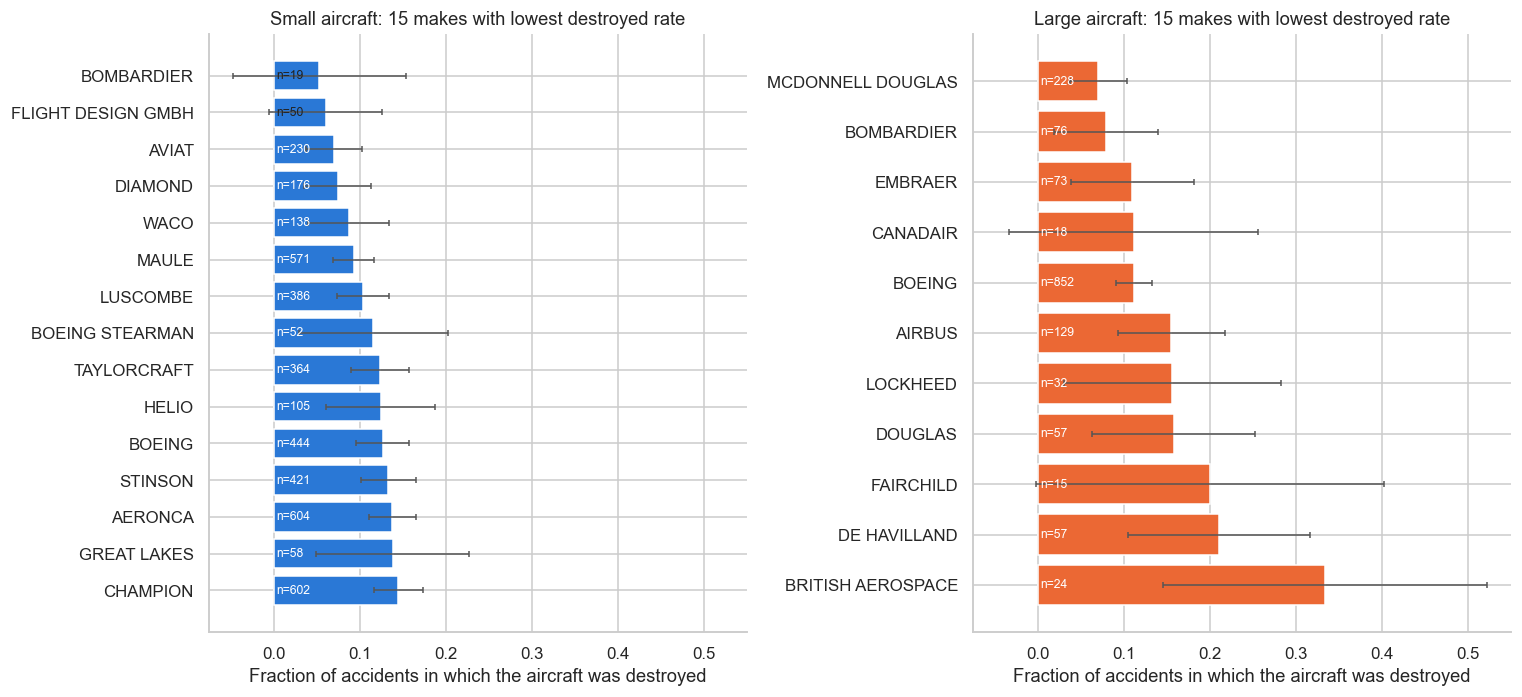

,n,destroyed_rate,destroyed_ci95
Make,,,
BOMBARDIER,19,0.053,0.100
FLIGHT DESIGN GMBH,50,0.060,0.066
AVIAT,230,0.070,0.033
DIAMOND,176,0.074,0.039
WACO,138,0.087,0.047
MAULE,571,0.093,0.024
LUSCOMBE,386,0.104,0.030
BOEING STEARMAN,52,0.115,0.087
TAYLORCRAFT,364,0.124,0.034


,n,destroyed_rate,destroyed_ci95
Make,,,
MCDONNELL DOUGLAS,228,0.070,0.033
BOMBARDIER,76,0.079,0.061
EMBRAER,73,0.110,0.072
CANADAIR,18,0.111,0.145
BOEING,852,0.112,0.021
AIRBUS,129,0.155,0.062
LOCKHEED,32,0.156,0.126
DOUGLAS,57,0.158,0.095
FAIRCHILD,15,0.200,0.202


In [13]:
low_d_small = small_makes.nsmallest(15, 'destroyed_rate')
low_d_large = large_makes.nsmallest(15, 'destroyed_rate')

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharex=True)
for ax, tbl, name in zip(axes, [low_d_small, low_d_large], ['Small', 'Large']):
    ax.barh(tbl.index, tbl['destroyed_rate'], xerr=tbl['destroyed_ci95'], color=COL[name], error_kw={'ecolor': '#555', 'lw': 1, 'capsize': 2})
    for y, (m, r) in enumerate(tbl.iterrows()):
        ax.text(0.003, y, f"n={int(r['n'])}", va='center', fontsize=8, color='white' if r['destroyed_rate'] > 0.06 else '#222')
    ax.invert_yaxis()
    ax.set_title(f'{name} aircraft: 15 makes with lowest destroyed rate')
    ax.set_xlabel('Fraction of accidents in which the aircraft was destroyed'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig('images/makes_destroyed.png', bbox_inches='tight'); plt.show()
display(low_d_small[['n','destroyed_rate','destroyed_ci95']].round(3)); display(low_d_large[['n','destroyed_rate','destroyed_ci95']].round(3))

In [14]:
# combine both metrics: rank makes on the average of the two ranks
def combined(tbl):
    t = tbl[['n', 'mean_frac', 'destroyed_rate']].copy()
    t['rank_score'] = (t['mean_frac'].rank() + t['destroyed_rate'].rank()) / 2
    return t.sort_values('rank_score')
print('SMALL'); display(combined(small_makes).head(10).round(3))
print('LARGE'); display(combined(large_makes).head(10).round(3))
print('Baselines (all makes):'); display(overall.round(3))

SMALL


,n,mean_frac,destroyed_rate,rank_score
Make,,,,
BOMBARDIER,19,0.075,0.053,1.0
WACO,138,0.103,0.087,3.5
MAULE,571,0.154,0.093,5.5
HELIO,105,0.141,0.124,7.0
BOEING,444,0.164,0.126,8.5
AVIAT,230,0.207,0.070,9.0
BOEING STEARMAN,52,0.192,0.115,9.5
GREAT LAKES,58,0.164,0.138,10.5
DIAMOND,176,0.234,0.074,10.5


LARGE


,n,mean_frac,destroyed_rate,rank_score
Make,,,,
MCDONNELL DOUGLAS,228,0.036,0.070,1.0
BOMBARDIER,76,0.084,0.079,2.5
CANADAIR,18,0.076,0.111,3.0
BOEING,852,0.105,0.112,4.5
EMBRAER,73,0.116,0.110,4.5
LOCKHEED,32,0.108,0.156,6.0
AIRBUS,129,0.140,0.155,6.5
DOUGLAS,57,0.166,0.158,8.0
FAIRCHILD,15,0.173,0.200,9.0


Baselines (all makes):


,n,mean_frac,destroyed_rate
Size,,,
Large,1566,0.107,0.118
Small,58424,0.275,0.214


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [ ]:
### Discussion - makes

**Context.** Small aircraft: on average 27.5% of occupants are fatally/seriously injured and 21.4% of aircraft are destroyed. Large aircraft: 10.7% and 11.8%. Large aircraft are safer per accident. Only 11 large makes have 10+ accidents.

**Small aircraft.** The injury fraction is bimodal (violin plot): in most accidents nobody is seriously hurt (0) and in a minority everybody is (1).
- Best-supported: Maule (n=571; 15.4%, 9.3% destroyed), Aviat, Waco, Helio, Diamond.
- Promising but not conclusive: Bombardier small models (7.5%, 5.3% destroyed) but only n=19, so the confidence interval is too wide.
- Benchmarks: Cessna (24.1%), Piper (29.9%), Beech (36.9%) and Mooney (36.3%) are at or above the baseline.

**Large aircraft.** McDonnell Douglas (n=228) is best at 3.6% injured and 7.0% destroyed. Boeing (n=852) is 10.5% / 11.2%, tightly estimated. Bombardier and Embraer are good with wider uncertainty. Airbus (14.0%) and De Havilland (20.1%) are weaker.

**Caveats.** Accident data have no flight hours, so these are risk-given-an-accident figures, not accident rates. Differences also reflect the mix of operations.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

large plane types with >= 10 accidents: 33


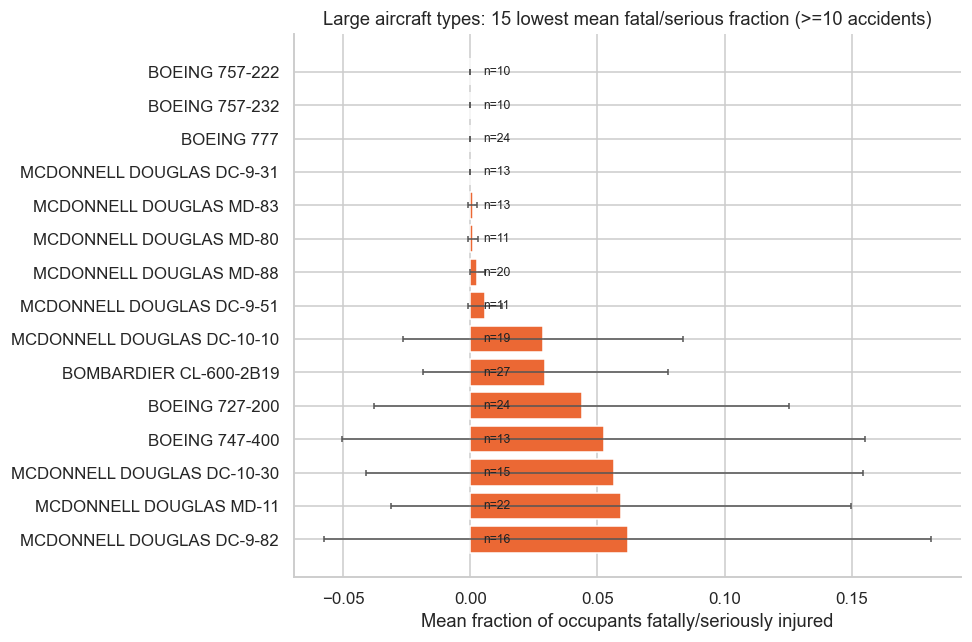

,n,mean_frac,frac_ci95,destroyed_rate
Plane.Type,,,,
BOEING 757-222,10,0.000,0.000,0.000
BOEING 757-232,10,0.000,0.000,0.000
BOEING 777,24,0.000,0.000,0.042
MCDONNELL DOUGLAS DC-9-31,13,0.000,0.000,0.000
MCDONNELL DOUGLAS MD-83,13,0.001,0.002,0.077
MCDONNELL DOUGLAS MD-80,11,0.001,0.002,0.000
MCDONNELL DOUGLAS MD-88,20,0.003,0.003,0.000
MCDONNELL DOUGLAS DC-9-51,11,0.006,0.007,0.091
MCDONNELL DOUGLAS DC-10-10,19,0.029,0.055,0.053


In [15]:
MIN_TYPE = 10   # at least 10 accidents per plane type
large_types_tbl = safety_table(large, 'Plane.Type', MIN_TYPE)
print('large plane types with >= 10 accidents:', len(large_types_tbl))
low_lt = large_types_tbl.nsmallest(15, 'mean_frac')

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(low_lt.index, low_lt['mean_frac'], xerr=low_lt['frac_ci95'], color=COL['Large'], error_kw={'ecolor': '#555', 'lw': 1, 'capsize': 2})
for y, (m, r) in enumerate(low_lt.iterrows()):
    ax.text(0.005, y, f"n={int(r['n'])}", va='center', fontsize=8, color='#222')
ax.invert_yaxis(); ax.set_xlabel('Mean fraction of occupants fatally/seriously injured')
ax.set_title('Large aircraft types: 15 lowest mean fatal/serious fraction (>=10 accidents)')
plt.tight_layout(); plt.savefig('images/large_types_mean.png', bbox_inches='tight'); plt.show()
low_lt[['n','mean_frac','frac_ci95','destroyed_rate']].round(3)

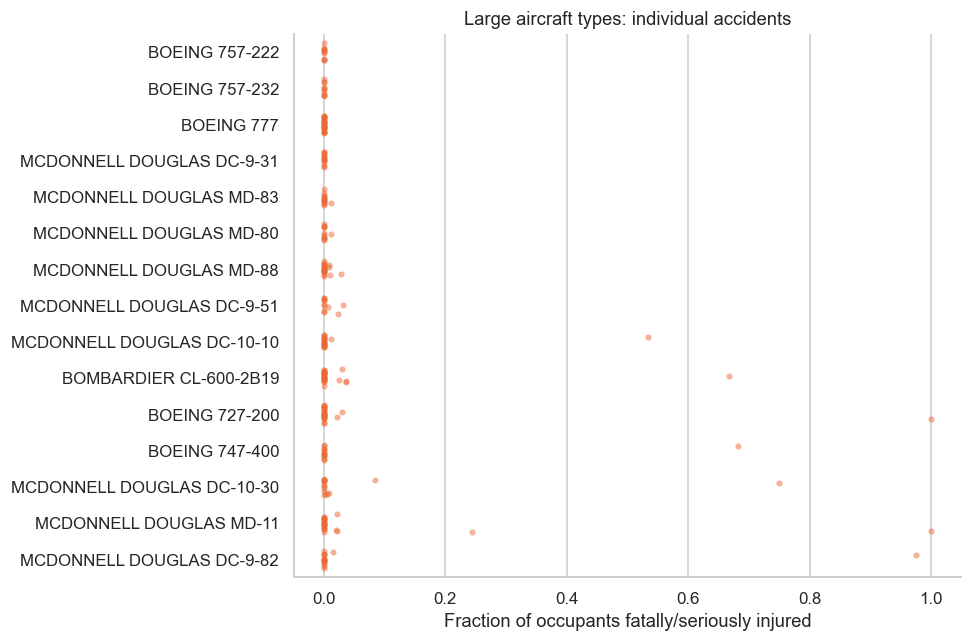

In [16]:
plt.figure(figsize=(9, 6))
sns.stripplot(data=large[large['Plane.Type'].isin(low_lt.index)], x='Fatal.Serious.Fraction', y='Plane.Type', order=low_lt.index,
              orient='h', jitter=0.25, alpha=0.5, size=4, color=COL['Large'])
plt.title('Large aircraft types: individual accidents'); plt.xlabel('Fraction of occupants fatally/seriously injured'); plt.ylabel('')
plt.tight_layout(); plt.savefig('images/large_types_strip.png', bbox_inches='tight'); plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

small plane types with >= 10 accidents: 741


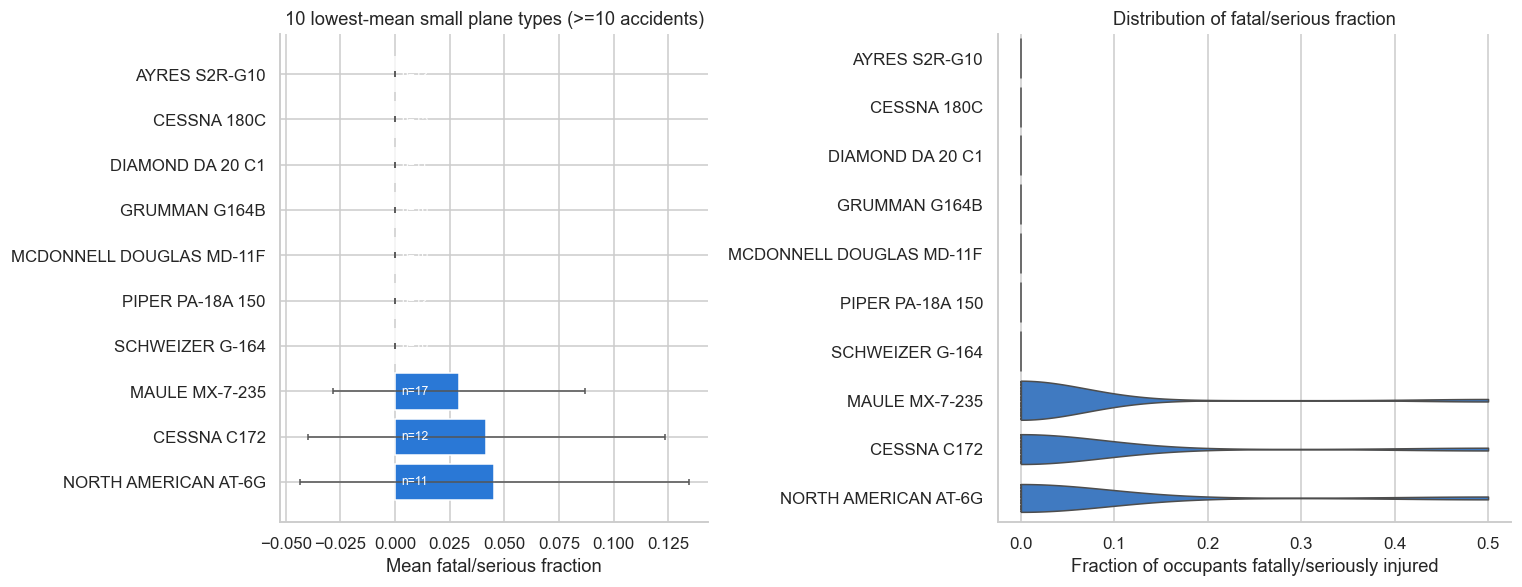

,n,mean_frac,frac_ci95,destroyed_rate
Plane.Type,,,,
AYRES S2R-G10,12,0.000,0.000,0.167
CESSNA 180C,15,0.000,0.000,0.067
DIAMOND DA 20 C1,11,0.000,0.000,0.000
GRUMMAN G164B,16,0.000,0.000,0.062
MCDONNELL DOUGLAS MD-11F,10,0.000,0.000,0.100
PIPER PA-18A 150,12,0.000,0.000,0.000
SCHWEIZER G-164,10,0.000,0.000,0.000
MAULE MX-7-235,17,0.029,0.058,0.000
CESSNA C172,12,0.042,0.082,0.000


In [17]:
small_types_tbl = safety_table(small, 'Plane.Type', MIN_TYPE)
print('small plane types with >= 10 accidents:', len(small_types_tbl))
low_st = small_types_tbl.nsmallest(10, 'mean_frac')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1, 1.2]})
axes[0].barh(low_st.index, low_st['mean_frac'], xerr=low_st['frac_ci95'], color=COL['Small'], error_kw={'ecolor': '#555', 'lw': 1, 'capsize': 2})
for y, (m, r) in enumerate(low_st.iterrows()):
    axes[0].text(0.003, y, f"n={int(r['n'])}", va='center', fontsize=8, color='white')
axes[0].invert_yaxis(); axes[0].set_xlabel('Mean fatal/serious fraction'); axes[0].set_title('10 lowest-mean small plane types (>=10 accidents)')
sns.violinplot(data=small[small['Plane.Type'].isin(low_st.index)], x='Fatal.Serious.Fraction', y='Plane.Type', order=low_st.index,
               orient='h', cut=0, inner='quartile', color=COL['Small'], linewidth=1, ax=axes[1])
axes[1].set_title('Distribution of fatal/serious fraction'); axes[1].set_ylabel(''); axes[1].set_xlabel('Fraction of occupants fatally/seriously injured')
plt.tight_layout(); plt.savefig('images/small_types.png', bbox_inches='tight'); plt.show()
low_st[['n','mean_frac','frac_ci95','destroyed_rate']].round(3)

In [18]:
robust_small = safety_table(small, 'Plane.Type', 30).nsmallest(10, 'mean_frac')
robust_large = safety_table(large, 'Plane.Type', 20).nsmallest(10, 'mean_frac')
print('SMALL, >=30 accidents'); display(robust_small[['n','mean_frac','frac_ci95','destroyed_rate']].round(3))
print('LARGE, >=20 accidents'); display(robust_large[['n','mean_frac','frac_ci95','destroyed_rate']].round(3))
print('all small plane types (>=10): mean of means =', round(small_types_tbl['mean_frac'].mean(), 3))

SMALL, >=30 accidents


,n,mean_frac,frac_ci95,destroyed_rate
Plane.Type,,,,
PIPER PA-18-160,31,0.048,0.070,0.032
BEECH C-23,33,0.061,0.083,0.091
CESSNA 180A,56,0.071,0.068,0.036
BOEING E75,33,0.076,0.087,0.121
PIPER PA-20,122,0.078,0.047,0.057
CESSNA 185E,34,0.078,0.078,0.059
CESSNA 185F,100,0.083,0.051,0.090
BEECH 1900D,46,0.086,0.081,0.087
CESSNA A185E,63,0.088,0.060,0.032


LARGE, >=20 accidents


,n,mean_frac,frac_ci95,destroyed_rate
Plane.Type,,,,
BOEING 777,24,0.000,0.000,0.042
MCDONNELL DOUGLAS MD-88,20,0.003,0.003,0.000
BOMBARDIER CL-600-2B19,27,0.029,0.048,0.037
BOEING 727-200,24,0.044,0.082,0.042
MCDONNELL DOUGLAS MD-11,22,0.059,0.090,0.136
BOEING 737-300,25,0.066,0.085,0.120
BOEING 747,31,0.068,0.088,0.065
BOEING 767,23,0.100,0.116,0.130
BOEING 737,121,0.134,0.058,0.107


all small plane types (>=10): mean of means = 0.303


### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [ ]:
### Discussion - specific plane types

**Large (>=10 accidents, 33 types).** Boeing 757-222/757-232, Boeing 777 and McDonnell Douglas DC-9-31 and MD-80/83/88 have a mean fraction near zero; the strip plot shows nearly all their accidents are minor events (turbulence, ground damage). With >=20 accidents the leaders are Boeing 777, MD-88, Bombardier CL-600-2B19, Boeing 727-200 and MD-11. The Boeing 737 (n=121) averages 13.4% +/- 5.8, a solid well-measured result. The DHC-6-300 Twin Otter is weakest (29.3% injured).

**Small (>=10 accidents, 741 types).** The mean of the means is about 30%. The 10 lowest types are all <= 5% but rest on only 10-17 accidents each ("winner's curse" - picking the best of 741). With >=30 accidents the robust leaders are Piper PA-18-160 (4.8%), Beech C-23, Cessna 180A, Piper PA-20 (n=122) and the Cessna 185 family, far below the 30% average.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

In [ ]:
Factor 1: Weather condition

n  mean_frac  destroyed_rate
Size  Weather.Condition                                  
Large IMC                  210      0.218           0.248
      VMC                  946      0.056           0.059
Small IMC                 4597      0.684           0.599
      VMC                51717      0.225           0.171

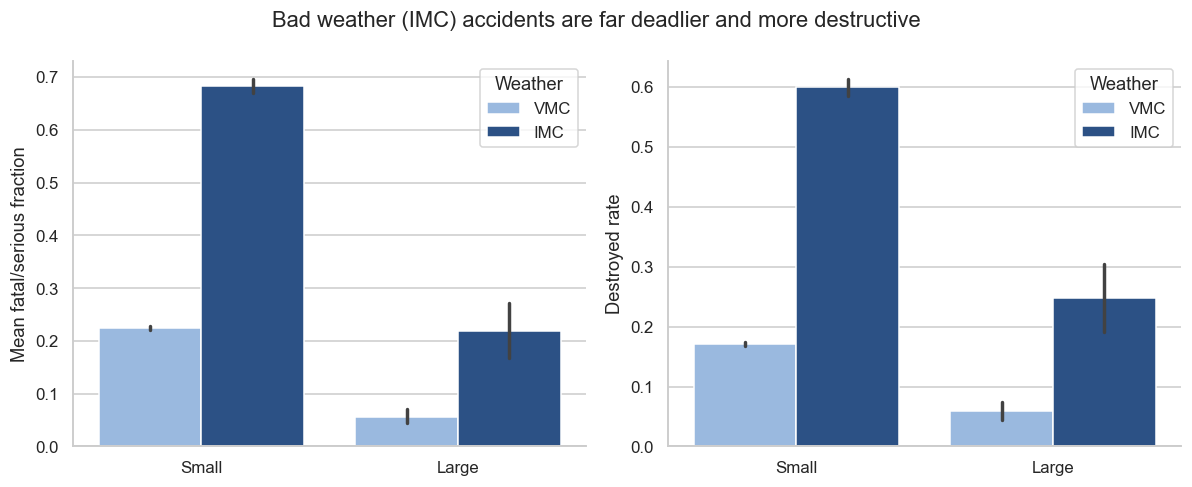

Large: destroyed vs weather chi-square p = 6.47e-17 | fatal/serious fraction Mann-Whitney p = 2.74e-16
Small: destroyed vs weather chi-square p = 0.00e+00 | fatal/serious fraction Mann-Whitney p = 0.00e+00


In [19]:
from scipy import stats
w = df.dropna(subset=['Weather.Condition'])
wt = w.groupby(['Size', 'Weather.Condition']).agg(n=('Destroyed','size'), mean_frac=('Fatal.Serious.Fraction','mean'), destroyed_rate=('Destroyed','mean')).round(3)
display(wt)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, metric, lab in zip(axes, ['Fatal.Serious.Fraction', 'Destroyed'], ['Mean fatal/serious fraction', 'Destroyed rate']):
    sns.barplot(data=w, x='Size', y=metric, hue='Weather.Condition', order=['Small', 'Large'], hue_order=['VMC', 'IMC'],
                palette=['#8fb8ea', '#1d4f94'], errorbar=('ci', 95), ax=ax)
    ax.set_ylabel(lab); ax.set_xlabel(''); ax.legend(title='Weather')
fig.suptitle('Bad weather (IMC) accidents are far deadlier and more destructive'); plt.tight_layout()
plt.savefig('images/weather.png', bbox_inches='tight'); plt.show()

for name, sub in w.groupby('Size'):
    ct = pd.crosstab(sub['Weather.Condition'], sub['Destroyed'])
    chi2, p_d, _, _ = stats.chi2_contingency(ct)
    a = sub[sub['Weather.Condition']=='VMC']['Fatal.Serious.Fraction']; b = sub[sub['Weather.Condition']=='IMC']['Fatal.Serious.Fraction']
    u, p_f = stats.mannwhitneyu(a, b)
    print(f'{name}: destroyed vs weather chi-square p = {p_d:.2e} | fatal/serious fraction Mann-Whitney p = {p_f:.2e}')

In [ ]:
**Finding:** Small aircraft: an IMC accident injures 68.4% of occupants vs 22.5% in VMC, and destroys the aircraft 59.9% vs 17.1%. Large aircraft: 21.8% vs 5.6% injured and 24.8% vs 5.9% destroyed. All differences are significant (p < 1e-15). IMC accidents are 3-4x deadlier: loss of visual reference leads to loss of control at speed. Implication: weather exposure should be a major pricing factor.

In [ ]:
Factor 2: Number of engines

n  mean_frac  destroyed_rate
Size  Number.of.Engines                                  
Large 2                    840      0.071           0.080
      3                    231      0.036           0.043
      4                    135      0.112           0.104
Small 1                  48777      0.251           0.189
      2                   7341      0.354           0.319
      3                     51      0.072           0.157
      4                    148      0.212           0.243

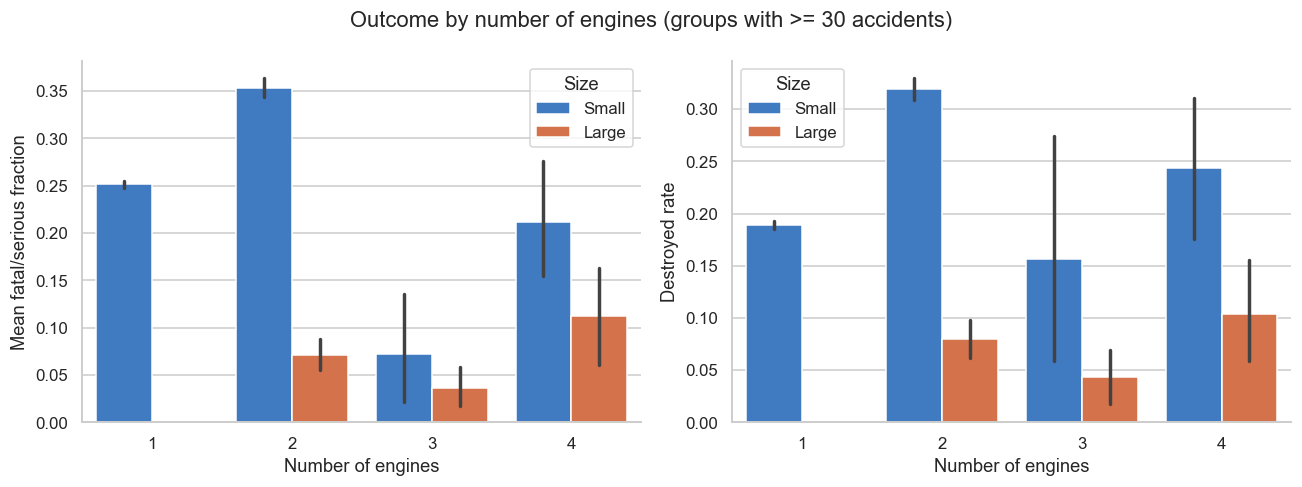

Large: destroyed vs engines chi-square p = 7.45e-02 | fatal/serious fraction Kruskal-Wallis p = 5.67e-01
Small: destroyed vs engines chi-square p = 6.88e-144 | fatal/serious fraction Kruskal-Wallis p = 2.55e-83


In [20]:
e = df.dropna(subset=['Number.of.Engines']).copy()
e['Number.of.Engines'] = e['Number.of.Engines'].astype(int)
et = e.groupby(['Size', 'Number.of.Engines']).agg(n=('Destroyed','size'), mean_frac=('Fatal.Serious.Fraction','mean'), destroyed_rate=('Destroyed','mean')).round(3)
display(et)

e = e[e.groupby(['Size','Number.of.Engines'])['Destroyed'].transform('size') >= 30]    # only groups with >= 30 accidents
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, lab in zip(axes, ['Fatal.Serious.Fraction', 'Destroyed'], ['Mean fatal/serious fraction', 'Destroyed rate']):
    sns.barplot(data=e, x='Number.of.Engines', y=metric, hue='Size', hue_order=['Small', 'Large'], palette=COL, errorbar=('ci', 95), ax=ax)
    ax.set_ylabel(lab); ax.set_xlabel('Number of engines')
fig.suptitle('Outcome by number of engines (groups with >= 30 accidents)'); plt.tight_layout()
plt.savefig('images/engines.png', bbox_inches='tight'); plt.show()

for name, sub in e.groupby('Size'):
    ct = pd.crosstab(sub['Number.of.Engines'], sub['Destroyed'])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    groups = [g['Fatal.Serious.Fraction'].values for _, g in sub.groupby('Number.of.Engines')]
    print(f'{name}: destroyed vs engines chi-square p = {p:.2e} | fatal/serious fraction Kruskal-Wallis p = {stats.kruskal(*groups)[1]:.2e}')

In [ ]:
**Finding:** For small aircraft, more engines do not mean safer. Twin-engine (n=7,341): 35.4% injured and 31.9% destroyed vs single-engine (n=48,777): 25.1% and 18.9% (p < 1e-80). Twins are heavier, faster and fly more in instrument conditions. This is an association; we have not controlled for weather or pilot experience. For large aircraft engine count makes no significant difference (p = 0.075 and 0.57). Implication: don't give a blanket discount for multi-engine light aircraft.

In [ ]:
Bonus factor 3: Phase of flight

,n,mean_frac,destroyed_rate
Broad.phase.of.flight,,,
Taxi,1520,0.016,0.022
Landing,12020,0.035,0.043
Standing,516,0.080,0.124
Takeoff,8992,0.226,0.219
Go-around,1170,0.300,0.288
Descent,1267,0.339,0.327
Approach,4595,0.352,0.299
Cruise,7149,0.352,0.344
Climb,1456,0.413,0.417


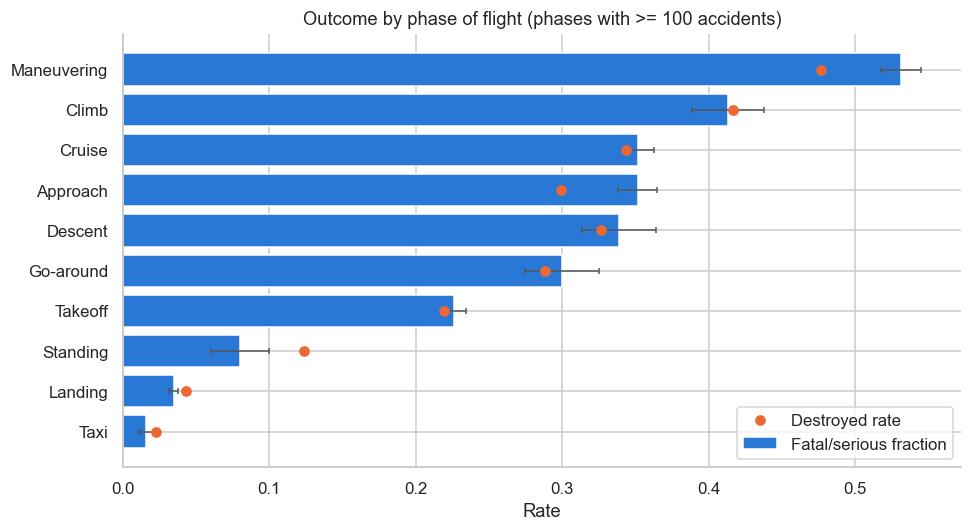

In [21]:
p = df.dropna(subset=['Broad.phase.of.flight'])
pt = safety_table(p, 'Broad.phase.of.flight', 100).sort_values('mean_frac')
display(pt[['n', 'mean_frac', 'destroyed_rate']].round(3))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(pt.index, pt['mean_frac'], xerr=pt['frac_ci95'], color='#2a78d6', error_kw={'ecolor': '#555', 'lw': 1, 'capsize': 2}, label='Fatal/serious fraction')
ax.plot(pt['destroyed_rate'], range(len(pt)), 'o', color='#eb6834', label='Destroyed rate')
ax.set_xlabel('Rate'); ax.legend(); ax.set_title('Outcome by phase of flight (phases with >= 100 accidents)')
plt.tight_layout(); plt.savefig('images/phase.png', bbox_inches='tight'); plt.show()

In [ ]:
**Finding:** Taxi (1.6% injured, 2.2% destroyed) and Landing (3.5%, 4.3%) are mostly minor. Maneuvering (53.1%, 47.7%), Climb (41.3%), Cruise (35.2%) and Approach (35.2%) are the deadliest. Low-speed ground events damage aircraft but leave people unhurt; in-flight upsets leave little room to recover.